In [25]:
import h5py
import matplotlib.pyplot as plt
import os
import numpy as np
import vector as vec
import awkward as ak
from scipy.stats import norm

In [26]:
file_path = "../data/raw/tt_hadronic_testing.h5"

with h5py.File(file_path, 'r') as f:
    # FRt1 targets
    frt1_b = f['TARGETS/FRt1/b'][:]
    frt1_mask = f['TARGETS/FRt1/mask'][:]
    frt1_pt = f['TARGETS/FRt1/pt'][:]
    frt1_q1 = f['TARGETS/FRt1/q1'][:]
    frt1_q2 = f['TARGETS/FRt1/q2'][:]

    # FRt2 targets
    frt2_b = f['TARGETS/FRt2/b'][:]
    frt2_mask = f['TARGETS/FRt2/mask'][:]
    frt2_pt = f['TARGETS/FRt2/pt'][:]
    frt2_q1 = f['TARGETS/FRt2/q1'][:]
    frt2_q2 = f['TARGETS/FRt2/q2'][:]

    # Optional: Load BoostedJet inputs if you need them
    fj_eta = f['INPUTS/BoostedJets/fj_eta'][:]
    fj_phi = f['INPUTS/BoostedJets/fj_phi'][:]
    fj_mass = f['INPUTS/BoostedJets/fj_mass'][:]
    fj_pt = f['INPUTS/BoostedJets/fj_pt'][:]


In [27]:
print(ak.type(frt1_b))
print(ak.type(frt1_mask))
print(ak.type(frt1_pt))
print(ak.type(frt1_q1))
print(ak.type(frt1_q2))

294459 * int64
294459 * bool
294459 * float64
294459 * int64
294459 * int64


In [28]:
#define the b/q1/q2 values for each top
with h5py.File(file_path, 'r') as f:
    frt1_b = f['TARGETS/FRt1/b'][:]
    frt1_q1 = f['TARGETS/FRt1/q1'][:]
    frt1_q2 = f['TARGETS/FRt1/q2'][:]
    
    frt2_b = f['TARGETS/FRt2/b'][:]
    frt2_q1 = f['TARGETS/FRt2/q1'][:]
    frt2_q2 = f['TARGETS/FRt2/q2'][:]

1- all true masks - mass for top targets
2- all 6 sets must be unique!!

In [29]:
has_2_tops = frt1_mask & frt2_mask

In [30]:
jet_index_mtrx = np.vstack([frt1_b, frt1_q1, frt1_q2, frt2_b, frt2_q1, frt2_q2]).T
jim_sel = jet_index_mtrx[has_2_tops]
print(jim_sel)

[[5 3 0 4 2 1]
 [0 6 4 3 1 2]
 [2 1 4 0 5 3]
 ...
 [2 3 1 0 5 4]
 [5 2 1 3 4 0]
 [3 2 1 0 6 4]]


In [31]:
_, unique_counts = np.unique(jim_sel, return_counts = True, axis =1)

In [32]:
all_6_jets_unique = unique_counts == 6
print(all_6_jets_unique)

[False False False False False False]


In [33]:
n_unique_jets = np.array([len(np.unique(row)) for row in jim_sel])
all_6_jets_unique_sel = n_unique_jets == 6
all_6_jets_unique = np.zeros_like(has_2_tops, dtype=bool)
all_6_jets_unique[has_2_tops] = all_6_jets_unique_sel
final_event_preselection = has_2_tops & all_6_jets_unique

In [34]:
final_event_preselection = has_2_tops & all_6_jets_unique
print(final_event_preselection)
print(np.sum(final_event_preselection))

[False False False ... False False False]
3203


In [35]:
#define the b/q1/q2 values for each top
with h5py.File(file_path, 'r') as f:
    frt1_b = f['TARGETS/FRt1/b'][:][final_event_preselection]
    frt1_q1 = f['TARGETS/FRt1/q1'][:][final_event_preselection]
    frt1_q2 = f['TARGETS/FRt1/q2'][:][final_event_preselection]
    
    frt2_b = f['TARGETS/FRt2/b'][:][final_event_preselection]
    frt2_q1 = f['TARGETS/FRt2/q1'][:][final_event_preselection]
    frt2_q2 = f['TARGETS/FRt2/q2'][:][final_event_preselection]
    
#making the 4momentum with the masses for top1
with h5py.File(file_path, 'r') as f:
    eta = (f['INPUTS/Jets/eta'][:][final_event_preselection])
    phi = (f['INPUTS/Jets/phi'][:][final_event_preselection])
    pt = (f['INPUTS/Jets/pt'][:][final_event_preselection])
    mass = (f['INPUTS/Jets/mass'][:][final_event_preselection])
    
with h5py.File(file_path, 'r') as f:
    frt1_mask = f['TARGETS/FRt1/mask'][:]
    # frt1_indices = np.where(frt1_mask)
    # print("frt1 indices that have true values: ", frt1_indices)

    frt2_mask = f['TARGETS/FRt2/mask'][:]
    # frt2_indices = np.where(frt2_mask)
    # print("frt2 indices that have true values: ", frt2_indices)

frt1_mask = frt1_mask[final_event_preselection]
frt2_mask = frt2_mask[final_event_preselection]

frt1_eta = eta[frt1_mask]
frt1_phi = phi[frt1_mask]
frt1_pt = pt[frt1_mask]
frt1_mass = mass[frt1_mask]

jets = vec.arr({
    "eta": frt1_eta,
    "phi": frt1_phi, 
    "pt": frt1_pt,
    "mass": frt1_mass
    })
#add masks

#use on test dataset!
frt1_b = (frt1_b[frt1_mask])
frt1_q1 = (frt1_q1[frt1_mask])
frt1_q2 = (frt1_q2[frt1_mask])

local_idx = ak.local_index(frt1_pt, axis=1)
#print(ak.type(local_idx))
#print(ak.sum(ak.is_none(frt1_b)))
# local_idx == frt1_b

# frt1_b_jets = ak.firsts(jets[local_idx == frt1_b])
#print(frt1_b)
# frt1_b_jets = jets[:, frt1_b]
frt1_bjets = jets[np.arange(len(jets)), frt1_b]
frt1_q1_jets = jets[np.arange(len(jets)), frt1_q1]
frt1_q2_jets = jets[np.arange(len(jets)), frt1_q2]

jets_sel = jets
frt1_b_sel = frt1_b
frt1_q1_sel = frt1_q1
frt1_q2_sel = frt1_q2

jets_sel[np.arange(len(jets_sel)), frt1_b_sel]
jets_sel[np.arange(len(jets_sel)), frt1_q1_sel]
jets_sel[np.arange(len(jets_sel)), frt1_q2_sel]

#masses!
mbqq = (frt1_bjets + frt1_q1_jets + frt1_q2_jets).mass
mqq = (frt1_q1_jets + frt1_q2_jets).mass

print("mbqq: ", mbqq)
print("mqq: ", mqq)

#making the 4momentum with the masses for top2
with h5py.File(file_path, 'r') as f:
    eta = (f['INPUTS/Jets/eta'][:][final_event_preselection])
    phi = (f['INPUTS/Jets/phi'][:][final_event_preselection])
    pt = (f['INPUTS/Jets/pt'][:][final_event_preselection])
    mass = (f['INPUTS/Jets/mass'][:][final_event_preselection])
    
frt2_eta = eta[frt2_mask]
frt2_phi = phi[frt2_mask]
frt2_pt = pt[frt2_mask]
frt2_mass = mass[frt2_mask]

jets = vec.arr({
    "eta": frt2_eta,
    "phi": frt2_phi, 
    "pt": frt2_pt,
    "mass": frt2_mass
    })

#add masks
frt2_b = (frt2_b[frt2_mask])
frt2_q1 = (frt2_q1[frt2_mask])
frt2_q2 = (frt2_q2[frt2_mask])

local_idx = ak.local_index(frt2_pt, axis=1)

frt2_bjets = jets[np.arange(len(jets)), frt2_b]
frt2_q1_jets = jets[np.arange(len(jets)), frt2_q1]
frt2_q2_jets = jets[np.arange(len(jets)), frt2_q2]

jets_sel2 = jets
frt2_b_sel = frt2_b
frt2_q1_sel = frt2_q1
frt2_q2_sel = frt2_q2

jets_sel2[np.arange(len(jets_sel2)), frt2_b_sel]
jets_sel2[np.arange(len(jets_sel2)), frt2_q1_sel]
jets_sel2[np.arange(len(jets_sel2)), frt2_q2_sel]

#masses!
mbqq2 = (frt2_bjets + frt2_q1_jets + frt2_q2_jets).mass
mqq2 = (frt2_q1_jets + frt2_q2_jets).mass

print("mbqq2: ", mbqq2)
print("mqq2: ", mqq2)

mbqq:  [157.46161  93.86799 181.06044 ... 206.94897 150.22026 175.21616]
mqq:  [ 78.948906  23.839817  92.678795 ...  91.82592  116.327515  73.9179  ]
mbqq2:  [156.70406 174.81973 181.93785 ... 135.97598 176.6304  144.93364]
mqq2:  [87.18537  76.71722  76.94869  ... 51.422455 84.25654  22.770723]


In [36]:
print(mbqq.shape)
print(mqq.shape)
print(mbqq2.shape)
print(mqq2.shape)

(3203,)
(3203,)
(3203,)
(3203,)


to do: 
- get rid of all zero mass objects
- fit gaussian to distribution
- find standard deviation of that gaussian
- include error bars in the plots and fittings

smaller bins on first two plots - set bins = 120 
find out how many events are in every bin

NEW PLOTS BELOW 12/1

In [37]:
bin_edges = np.arange(0, 1000, 120)

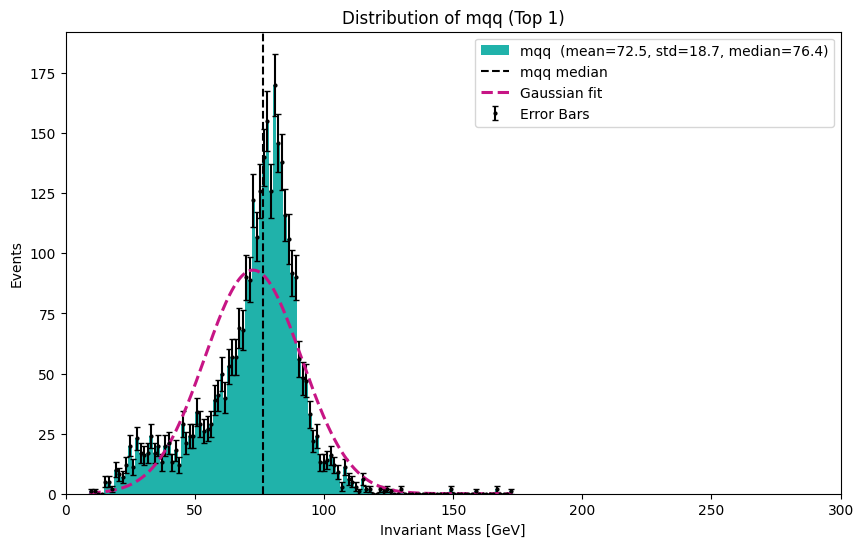

In [38]:
#mqq top 1
mqq_np = ak.to_numpy(mqq)
mqq_np = mqq_np[mqq_np > 0]

mqq_mean = np.mean(mqq_np)
mqq_median = np.median(mqq_np)
mqq_std = np.std(mqq_np)

mu, sigma = norm.fit(mqq_np)

plt.figure(figsize=(10, 6))
counts, bin_edges, _ = plt.hist(mqq_np, color='lightseagreen', bins=120, linewidth=1.8, label=f"mqq  (mean={mqq_mean:.1f}, std={mqq_std:.1f}, median={mqq_median:.1f})")
plt.axvline(mqq_median, color='black', linestyle='--', linewidth=1.5, label="mqq median")
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

errors = np.sqrt(counts)
plt.errorbar(bin_centers, counts, yerr=errors, fmt='o', markersize=2, color='black', ecolor='black', capsize=2, label='Error Bars')

x = np.linspace(bin_edges[0], bin_edges[-1], 500)
pdf = norm.pdf(x, mu, sigma)
pdf_scaled = pdf * (len(mqq_np) * (bin_edges[1] - bin_edges[0]))

plt.plot(x, pdf_scaled, linewidth=2.2, linestyle='--', color='mediumvioletred', label="Gaussian fit")

plt.xlabel("Invariant Mass [GeV]")
plt.ylabel("Events")
plt.title("Distribution of mqq (Top 1)")
plt.legend()
plt.xlim(0, 300)
plt.show()

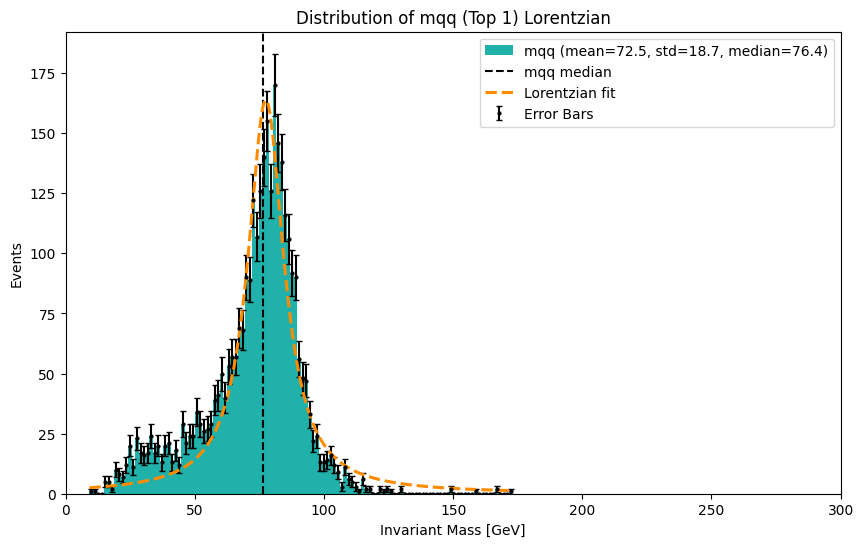

In [39]:
# CAUCHY MQQ1

from scipy.stats import cauchy

# mqq top 1
mqq_np = ak.to_numpy(mqq)
mqq_np = mqq_np[mqq_np > 0]

mqq_mean = np.mean(mqq_np)
mqq_median = np.median(mqq_np)
mqq_std = np.std(mqq_np)

# Lorentzian (Cauchy) fit
x0, gamma = cauchy.fit(mqq_np)   # location and scale

plt.figure(figsize=(10, 6))

counts, bin_edges, _ = plt.hist(
    mqq_np,
    color='lightseagreen',
    bins=120,
    linewidth=1.8,
    label=f"mqq (mean={mqq_mean:.1f}, std={mqq_std:.1f}, median={mqq_median:.1f})"
)

plt.axvline(
    mqq_median,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label="mqq median"
)

# Bin centers
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# Poisson errors
errors = np.sqrt(counts)
plt.errorbar(
    bin_centers,
    counts,
    yerr=errors,
    fmt='o',
    markersize=2,
    color='black',
    ecolor='black',
    capsize=2,
    label='Error Bars'
)

# Lorentzian PDF scaled to histogram
x = np.linspace(bin_edges[0], bin_edges[-1], 500)
pdf = cauchy.pdf(x, loc=x0, scale=gamma)
pdf_scaled = pdf * (len(mqq_np) * (bin_edges[1] - bin_edges[0]))

plt.plot(
    x,
    pdf_scaled,
    linewidth=2.2,
    linestyle='--',
    color='darkorange',
    label="Lorentzian fit"
)

plt.xlabel("Invariant Mass [GeV]")
plt.ylabel("Events")
plt.title("Distribution of mqq (Top 1) Lorentzian")
plt.legend()
plt.xlim(0, 300)
plt.show()


restrict the first two bins

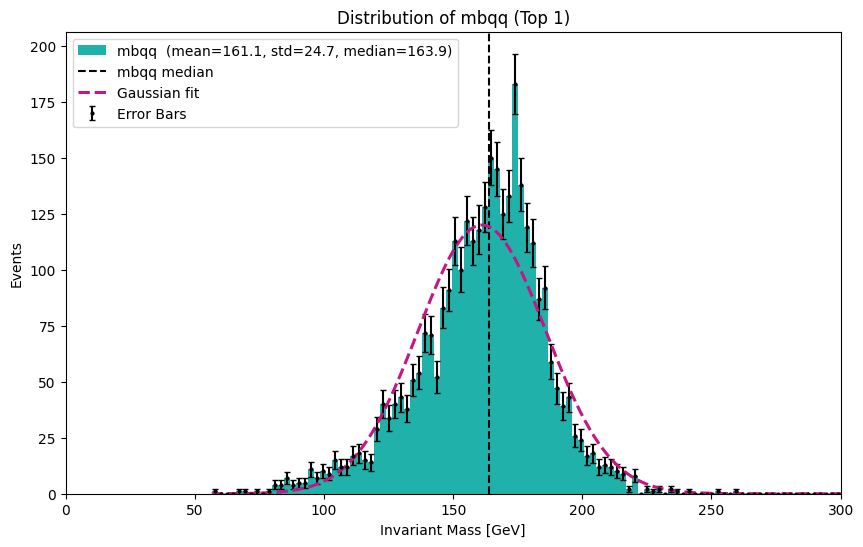

In [40]:
#mbqq top 1
mbqq_np = ak.to_numpy(mbqq)
mbqq_np = mbqq_np[mbqq_np > 0]

mbqq_mean = np.mean(mbqq_np)
mbqq_median = np.median(mbqq_np)
mbqq_std = np.std(mbqq_np)

mu, sigma = norm.fit(mbqq_np)


plt.figure(figsize=(10, 6))
counts, bin_edges, _ = plt.hist(mbqq_np, color='lightseagreen', bins=120, linewidth=1.8, label=f"mbqq  (mean={mbqq_mean:.1f}, std={mbqq_std:.1f}, median={mbqq_median:.1f})")
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
plt.axvline(mbqq_median, color='black', linestyle='--', linewidth=1.5, label="mbqq median")

errors = np.sqrt(counts)
plt.errorbar(bin_centers, counts, yerr=errors, fmt='o', markersize=2, color='black', ecolor='black', capsize=2, label='Error Bars')

x = np.linspace(bin_edges[0], bin_edges[-1], 500)
pdf = norm.pdf(x, mu, sigma)
pdf_scaled = pdf * (len(mbqq_np) * (bin_edges[1] - bin_edges[0]))

plt.plot(x, pdf_scaled, linewidth=2.2, linestyle='--', color='mediumvioletred', label="Gaussian fit")

plt.xlabel("Invariant Mass [GeV]")
plt.ylabel("Events")
plt.title("Distribution of mbqq (Top 1)")
plt.legend()
plt.xlim(0, 300)
plt.show()

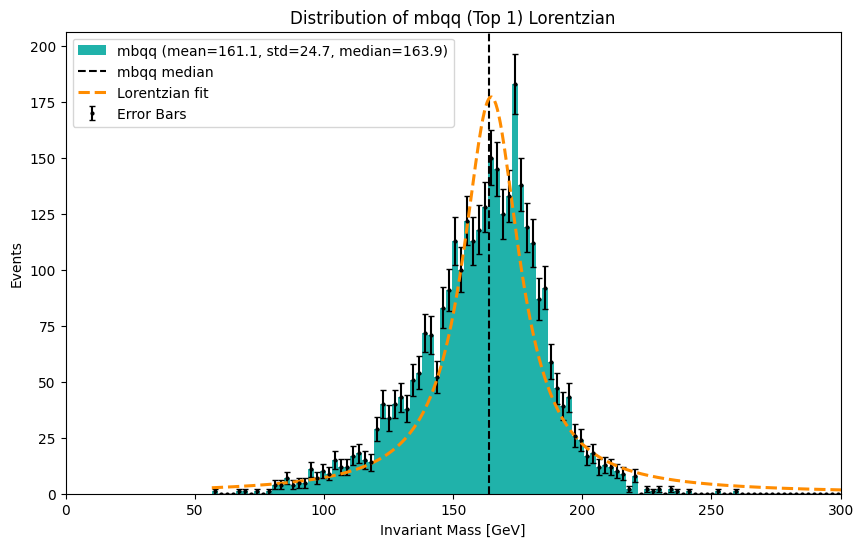

In [41]:
# CAUCHY MBQQ1

from scipy.stats import cauchy

# mbqq top 1
mbqq_np = ak.to_numpy(mbqq)
mbqq_np = mbqq_np[mbqq_np > 0]

mbqq_mean = np.mean(mbqq_np)
mbqq_median = np.median(mbqq_np)
mbqq_std = np.std(mbqq_np)

# Lorentzian (Cauchy) fit
x0, gamma = cauchy.fit(mbqq_np)

plt.figure(figsize=(10, 6))

counts, bin_edges, _ = plt.hist(
    mbqq_np,
    color='lightseagreen',
    bins=120,
    linewidth=1.8,
    label=f"mbqq (mean={mbqq_mean:.1f}, std={mbqq_std:.1f}, median={mbqq_median:.1f})"
)

plt.axvline(
    mbqq_median,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label="mbqq median"
)

# Bin centers (must be computed AFTER histogram)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# Poisson errors
errors = np.sqrt(counts)
plt.errorbar(
    bin_centers,
    counts,
    yerr=errors,
    fmt='o',
    markersize=2,
    color='black',
    ecolor='black',
    capsize=2,
    label='Error Bars'
)

# Lorentzian PDF scaled to histogram
x = np.linspace(bin_edges[0], bin_edges[-1], 500)
pdf = cauchy.pdf(x, loc=x0, scale=gamma)
pdf_scaled = pdf * (len(mbqq_np) * (bin_edges[1] - bin_edges[0]))

plt.plot(
    x,
    pdf_scaled,
    linewidth=2.2,
    linestyle='--',
    color='darkorange',
    label="Lorentzian fit"
)

plt.xlabel("Invariant Mass [GeV]")
plt.ylabel("Events")
plt.title("Distribution of mbqq (Top 1) Lorentzian")
plt.legend()
plt.xlim(0, 300)
plt.show()


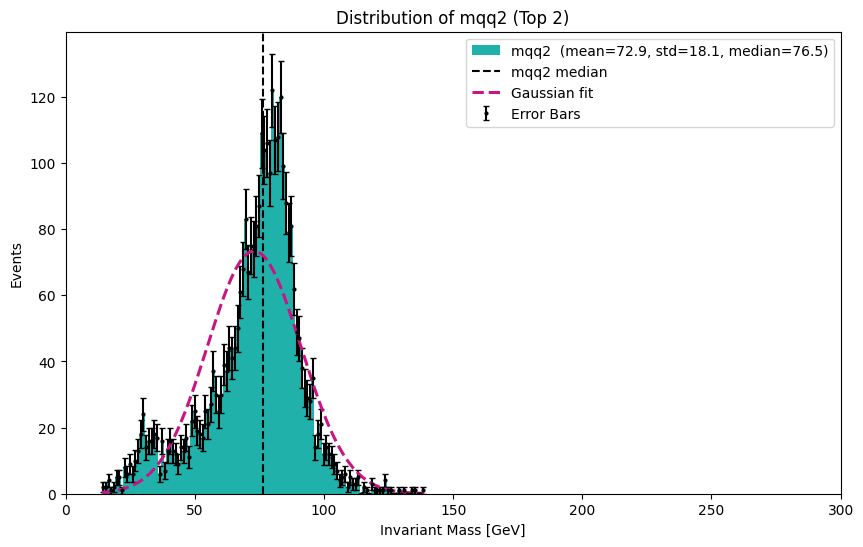

In [42]:
#mqq top 2
mqq2_np = ak.to_numpy(mqq2)
mqq2_np = mqq2_np[mqq2_np > 0]

mqq2_mean = np.mean(mqq2_np)
mqq2_median = np.median(mqq2_np)
mqq2_std = np.std(mqq2_np)

mu, sigma = norm.fit(mqq2_np)

plt.figure(figsize=(10, 6))
counts, bin_edges, _ = plt.hist(mqq2_np, color='lightseagreen', bins=120, linewidth=1.8, label=f"mqq2  (mean={mqq2_mean:.1f}, std={mqq2_std:.1f}, median={mqq2_median:.1f})")
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
plt.axvline(mqq2_median, color='black', linestyle='--', linewidth=1.5, label="mqq2 median")

errors = np.sqrt(counts)
plt.errorbar(bin_centers, counts, yerr=errors, fmt='o', markersize=2, color='black', ecolor='black', capsize=2, label='Error Bars')

x = np.linspace(bin_edges[0], bin_edges[-1], 500)
pdf = norm.pdf(x, mu, sigma)
pdf_scaled = pdf * (len(mqq_np) * (bin_edges[1] - bin_edges[0]))

plt.plot(x, pdf_scaled, linewidth=2.2, linestyle='--', color='mediumvioletred', label="Gaussian fit")

plt.xlabel("Invariant Mass [GeV]")
plt.ylabel("Events")
plt.title("Distribution of mqq2 (Top 2)")
plt.legend()
plt.xlim(0, 300)
plt.show()

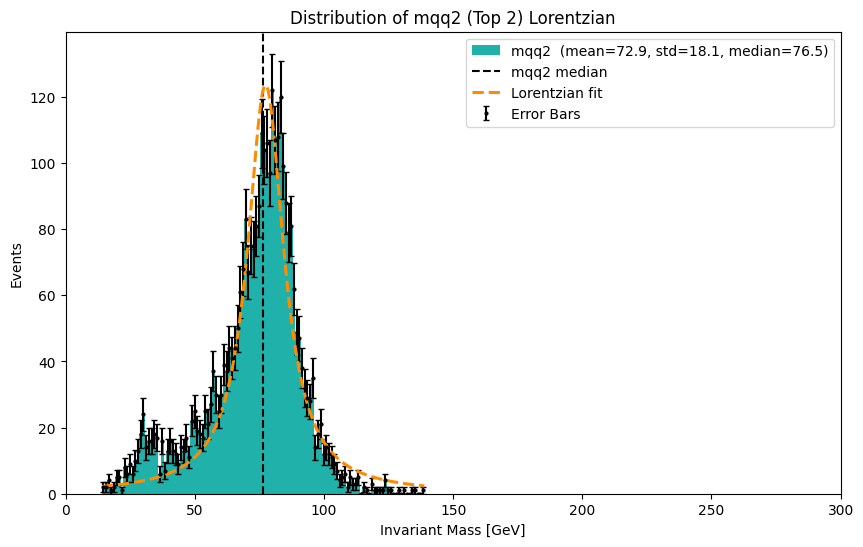

In [52]:
# CAUCHY MQQ2

import awkward as ak
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import cauchy

# mqq top 2
mqq2_np = ak.to_numpy(mqq2)
mqq2_np = mqq2_np[mqq2_np > 0]

mqq2_mean = np.mean(mqq2_np)
mqq2_median = np.median(mqq2_np)
mqq2_std = np.std(mqq2_np)

# Fit Lorentzian (Cauchy) distribution
loc, scale = cauchy.fit(mqq2_np)

plt.figure(figsize=(10, 6))
counts, bin_edges, _ = plt.hist(
    mqq2_np, color='lightseagreen', bins=120, linewidth=1.8,
    label=f"mqq2  (mean={mqq2_mean:.1f}, std={mqq2_std:.1f}, median={mqq2_median:.1f})"
)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
plt.axvline(mqq2_median, color='black', linestyle='--', linewidth=1.5, label="mqq2 median")

# Error bars
errors = np.sqrt(counts)
plt.errorbar(bin_centers, counts, yerr=errors, fmt='o', markersize=2, color='black', ecolor='black', capsize=2, label='Error Bars')

# Lorentzian PDF
x = np.linspace(bin_edges[0], bin_edges[-1], 500)
pdf = cauchy.pdf(x, loc=loc, scale=scale)
pdf_scaled = pdf * len(mqq2_np) * (bin_edges[1] - bin_edges[0])

plt.plot(x, pdf_scaled, linewidth=2.2, linestyle='--', color='darkorange', label="Lorentzian fit")

plt.xlabel("Invariant Mass [GeV]")
plt.ylabel("Events")
plt.title("Distribution of mqq2 (Top 2) Lorentzian")
plt.legend()
plt.xlim(0, 300)
plt.show()


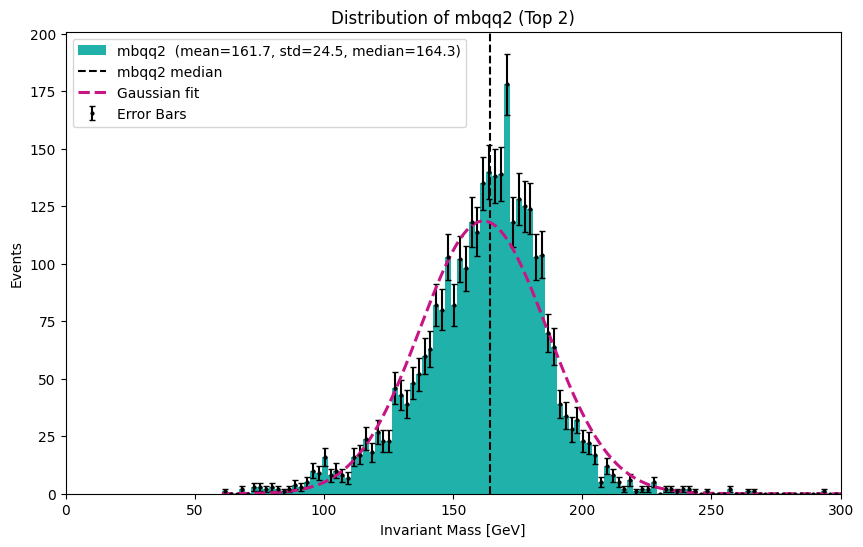

In [44]:
#mbqq top 2
mbqq2_np = ak.to_numpy(mbqq2)
mbqq2_np = mbqq2_np[mbqq2_np > 0]

mbqq2_mean = np.mean(mbqq2_np)
mbqq2_median = np.median(mbqq2_np)
mbqq2_std = np.std(mbqq2_np)

mu, sigma = norm.fit(mbqq2_np)

plt.figure(figsize=(10, 6))
counts, bin_edges, _ = plt.hist(mbqq2_np, color='lightseagreen', bins=120, linewidth=1.8, label=f"mbqq2  (mean={mbqq2_mean:.1f}, std={mbqq2_std:.1f}, median={mbqq2_median:.1f})")
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
plt.axvline(mbqq2_median, color='black', linestyle='--', linewidth=1.5, label="mbqq2 median")

errors = np.sqrt(counts)
plt.errorbar(bin_centers, counts, yerr=errors, fmt='o', markersize=2, color='black', ecolor='black', capsize=2, label='Error Bars')

x = np.linspace(bin_edges[0], bin_edges[-1], 500)
pdf = norm.pdf(x, mu, sigma)
pdf_scaled = pdf * (len(mqq_np) * (bin_edges[1] - bin_edges[0]))

plt.plot(x, pdf_scaled, linewidth=2.2, linestyle='--', color='mediumvioletred', label="Gaussian fit")

plt.xlabel("Invariant Mass [GeV]")
plt.ylabel("Events")
plt.title("Distribution of mbqq2 (Top 2)")
plt.legend()
plt.xlim(0, 300)
plt.show()

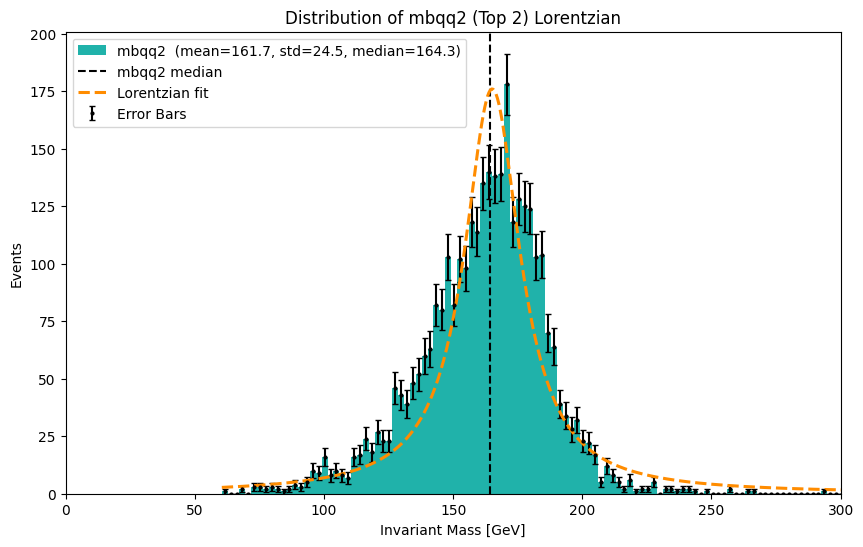

In [54]:
# CAUCHY MBQQ2

import awkward as ak
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import cauchy

# mbqq top 2
mbqq2_np = ak.to_numpy(mbqq2)
mbqq2_np = mbqq2_np[mbqq2_np > 0]

mbqq2_mean = np.mean(mbqq2_np)
mbqq2_median = np.median(mbqq2_np)
mbqq2_std = np.std(mbqq2_np)

# Fit Lorentzian (Cauchy) distribution
loc, scale = cauchy.fit(mbqq2_np)

plt.figure(figsize=(10, 6))
counts, bin_edges, _ = plt.hist(
    mbqq2_np, color='lightseagreen', bins=120, linewidth=1.8,
    label=f"mbqq2  (mean={mbqq2_mean:.1f}, std={mbqq2_std:.1f}, median={mbqq2_median:.1f})"
)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
plt.axvline(mbqq2_median, color='black', linestyle='--', linewidth=1.5, label="mbqq2 median")

# Error bars
errors = np.sqrt(counts)
plt.errorbar(bin_centers, counts, yerr=errors, fmt='o', markersize=2, color='black', ecolor='black', capsize=2, label='Error Bars')

# Lorentzian PDF
x = np.linspace(bin_edges[0], bin_edges[-1], 500)
pdf = cauchy.pdf(x, loc=loc, scale=scale)
pdf_scaled = pdf * len(mbqq2_np) * (bin_edges[1] - bin_edges[0])

plt.plot(x, pdf_scaled, linewidth=2.2, linestyle='--', color='darkorange', label="Lorentzian fit")

plt.xlabel("Invariant Mass [GeV]")
plt.ylabel("Events")
plt.title("Distribution of mbqq2 (Top 2) Lorentzian")
plt.legend()
plt.xlim(0, 300)
plt.show()


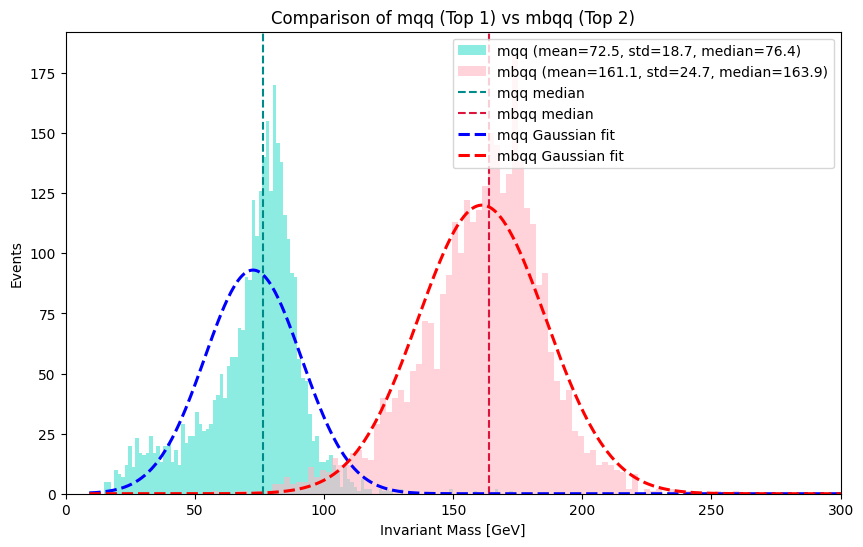

In [45]:
#all top1
#mqq top 1
mqq_np = ak.to_numpy(mqq)
mqq_np = mqq_np[mqq_np > 0]

mqq_mean = np.mean(mqq_np)
mqq_median = np.median(mqq_np)
mqq_std = np.std(mqq_np)
mu1, sigma1 = norm.fit(mqq_np)

#mbqq top 1
mbqq_np = ak.to_numpy(mbqq)
mbqq_np = mbqq_np[mbqq_np > 0]

mbqq_mean = np.mean(mbqq_np)
mbqq_median = np.median(mbqq_np)
mbqq_std = np.std(mbqq_np)
mu2, sigma2 = norm.fit(mbqq_np)

plt.figure(figsize=(10, 6))

counts1, bins1, _ = plt.hist(mqq_np, bins=120, alpha=0.6, color='turquoise', linewidth=1.8, label=f"mqq (mean={mqq_mean:.1f}, std={mqq_std:.1f}, median={mqq_median:.1f})")
counts2, bins2, _ = plt.hist(mbqq_np, bins=120, alpha=0.6, color='lightpink', linewidth=1.8, label=f"mbqq (mean={mbqq_mean:.1f}, std={mbqq_std:.1f}, median={mbqq_median:.1f})")

plt.axvline(mqq_median, color='darkcyan', linestyle='--', linewidth=1.5, label="mqq median")
plt.axvline(mbqq_median, color='crimson', linestyle='--', linewidth=1.5, label="mbqq median")

xmin = min(bins1[0], bins2[0])
xmax = max(bins1[-1], bins2[-1])
x = np.linspace(xmin, xmax, 500)

binw1 = bins1[1] - bins1[0]
binw2 = bins2[1] - bins2[0]

pdf1 = norm.pdf(x, mu1, sigma1) * len(mqq_np) * binw1
pdf2 = norm.pdf(x, mu2, sigma2) * len(mbqq_np) * binw2

plt.plot(x, pdf1, linestyle='--', color='blue', linewidth=2.2, label="mqq Gaussian fit")
plt.plot(x, pdf2, linestyle='--', color='red', linewidth=2.2, label="mbqq Gaussian fit")

plt.xlabel("Invariant Mass [GeV]")
plt.ylabel("Events")
plt.title("Comparison of mqq (Top 1) vs mbqq (Top 2)")
plt.legend()
plt.xlim(0, 300)
plt.show()

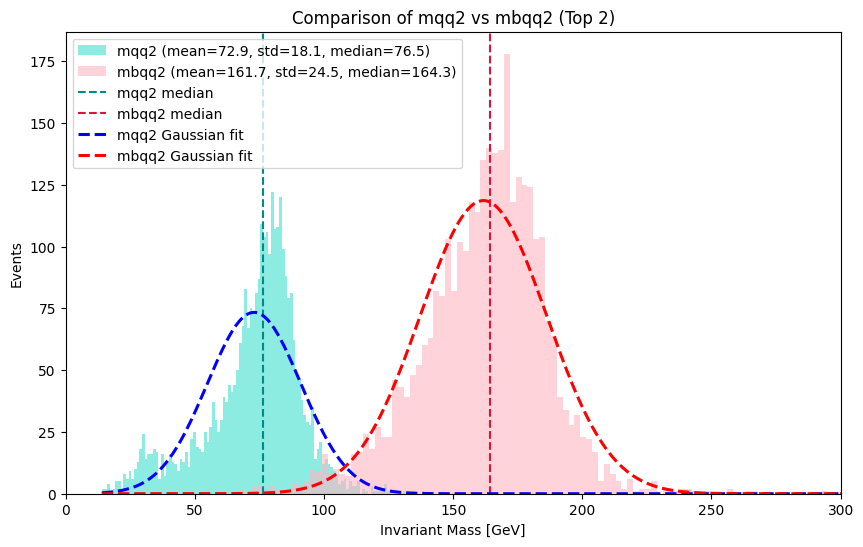

In [46]:
#all top 2
# mqq top 2
mqq2_np = ak.to_numpy(mqq2)
mqq2_np = mqq2_np[mqq2_np > 0]

mqq2_mean = np.mean(mqq2_np)
mqq2_median = np.median(mqq2_np)
mqq2_std = np.std(mqq2_np)
mu1, sigma1 = norm.fit(mqq2_np)

#mbqq top 2
mbqq2_np = ak.to_numpy(mbqq2)
mbqq2_np = mbqq2_np[mbqq2_np > 0]

mbqq2_mean = np.mean(mbqq2_np)
mbqq2_median = np.median(mbqq2_np)
mbqq2_std = np.std(mbqq2_np)
mu2, sigma2 = norm.fit(mbqq2_np)

plt.figure(figsize=(10, 6))

counts1, bins1, _ = plt.hist(mqq2_np, bins=120, alpha=0.6, color='turquoise', linewidth=1.8, label=f"mqq2 (mean={mqq2_mean:.1f}, std={mqq2_std:.1f}, median={mqq2_median:.1f})")
counts2, bins2, _ = plt.hist(mbqq2_np, bins=120, alpha=0.6, color='lightpink', linewidth=1.8, label=f"mbqq2 (mean={mbqq2_mean:.1f}, std={mbqq2_std:.1f}, median={mbqq2_median:.1f})")

plt.axvline(mqq2_median, color='darkcyan', linestyle='--', linewidth=1.5, label="mqq2 median")
plt.axvline(mbqq2_median, color='crimson', linestyle='--', linewidth=1.5, label="mbqq2 median")

xmin = min(bins1[0], bins2[0])
xmax = max(bins1[-1], bins2[-1])

x = np.linspace(xmin, xmax, 500)

binw1 = bins1[1] - bins1[0]
binw2 = bins2[1] - bins2[0]

pdf1 = norm.pdf(x, mu1, sigma1) * len(mqq2_np) * binw1
pdf2 = norm.pdf(x, mu2, sigma2) * len(mbqq2_np) * binw2

plt.plot(x, pdf1, linestyle='--', linewidth=2.2, color='blue', label="mqq2 Gaussian fit")
plt.plot(x, pdf2, linestyle='--', linewidth=2.2, color='red', label="mbqq2 Gaussian fit")

plt.xlabel("Invariant Mass [GeV]")
plt.ylabel("Events")
plt.title("Comparison of mqq2 vs mbqq2 (Top 2)")
plt.legend()
plt.xlim(0, 300)
plt.show()

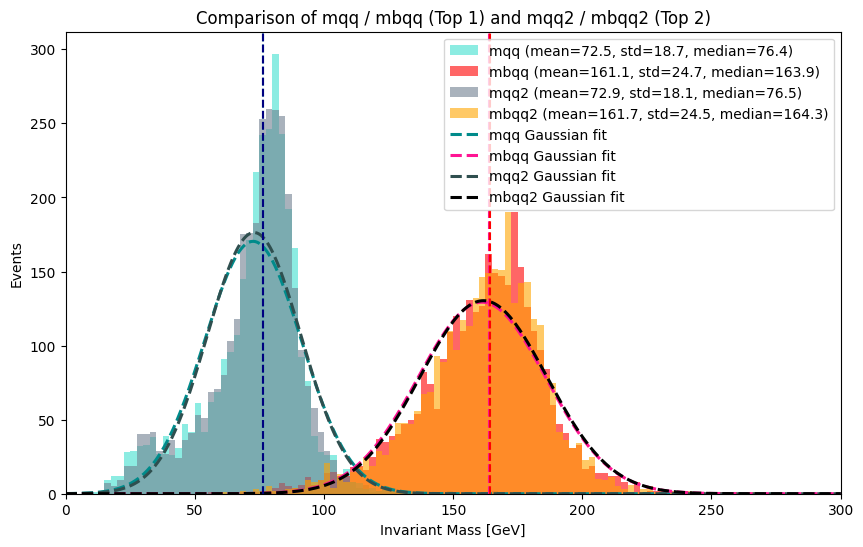

In [47]:
#full top1/top2

#top1
mqq_np  = ak.to_numpy(mqq);    mqq_np  = mqq_np[mqq_np > 0]
mbqq_np = ak.to_numpy(mbqq);   mbqq_np = mbqq_np[mbqq_np > 0]

#top2
mqq2_np  = ak.to_numpy(mqq2);   mqq2_np  = mqq2_np[mqq2_np > 0]
mbqq2_np = ak.to_numpy(mbqq2);  mbqq2_np = mbqq2_np[mbqq2_np > 0]


mu_mqq,  sigma_mqq  = norm.fit(mqq_np)
mu_mbqq, sigma_mbqq = norm.fit(mbqq_np)
mu_mqq2,  sigma_mqq2  = norm.fit(mqq2_np)
mu_mbqq2, sigma_mbqq2 = norm.fit(mbqq2_np)

plt.figure(figsize=(10, 6))

counts_base, bins, _ = plt.hist(mqq_np, bins=120, alpha=0, color='white')

xmin, xmax = 0, 300
bins = 120

counts1, bins1, _ = plt.hist(mqq_np, bins=bins, range=(xmin, xmax), alpha=0.6, color='turquoise', linewidth=1.8, label=f"mqq (mean={mqq_mean:.1f}, std={mqq_std:.1f}, median={mqq_median:.1f})")
counts2, bins2, _ = plt.hist(mbqq_np, bins=bins, range=(xmin, xmax), alpha=0.6, color='red', linewidth=1.8, label=f"mbqq (mean={mbqq_mean:.1f}, std={mbqq_std:.1f}, median={mbqq_median:.1f})")
counts3, bins3, _ = plt.hist(mqq2_np, bins=bins, range=(xmin, xmax), alpha=0.6, color='slategrey', linewidth=1.8, label=f"mqq2 (mean={mqq2_mean:.1f}, std={mqq2_std:.1f}, median={mqq2_median:.1f})")
counts4, bins4, _ = plt.hist(mbqq2_np, bins=bins, range=(xmin, xmax), alpha=0.6, color='orange', linewidth=1.8, label=f"mbqq2 (mean={mbqq2_mean:.1f}, std={mbqq2_std:.1f}, median={mbqq2_median:.1f})")

x = np.linspace(xmin, xmax, 800)
bin_width = (xmax - xmin) / bins

plt.plot(x, norm.pdf(x, mu_mqq, sigma_mqq) * len(mqq_np) * bin_width, '--', color='darkcyan', linewidth=2.2, label="mqq Gaussian fit")
plt.plot(x, norm.pdf(x, mu_mbqq, sigma_mbqq) * len(mbqq_np) * bin_width, '--', color='deeppink', linewidth=2.2, label="mbqq Gaussian fit")
plt.plot(x, norm.pdf(x, mu_mqq2, sigma_mqq2) * len(mqq2_np) * bin_width, '--', color='darkslategrey', linewidth=2.2, label="mqq2 Gaussian fit")
plt.plot(x, norm.pdf(x, mu_mbqq2, sigma_mbqq2) * len(mbqq2_np) * bin_width, '--', color='black', linewidth=2.2, label="mbqq2 Gaussian fit")

plt.axvline(np.median(mqq_np), color='darkcyan', linestyle='--', linewidth=1.5)
plt.axvline(np.median(mbqq_np), color='deeppink', linestyle='--', linewidth=1.5)
plt.axvline(np.median(mqq2_np), color='navy', linestyle='--', linewidth=1.5)
plt.axvline(np.median(mbqq2_np), color='red', linestyle='--', linewidth=1.5)

plt.xlabel("Invariant Mass [GeV]")
plt.ylabel("Events")
plt.title("Comparison of mqq / mbqq (Top 1) and mqq2 / mbqq2 (Top 2)")
plt.legend(fontsize=10)
plt.xlim(0, 300)
plt.show()

In [48]:
from scipy.stats import norm, cauchy, chi2
import numpy as np
import awkward as ak

datasets = {
    "Top1 mqq": mqq,
    "Top1 mbqq": mbqq,
    "Top2 mqq2": mqq2,
    "Top2 mbqq2": mbqq2
}

for name, data in datasets.items():
    print(f"\n=== {name} ===")

    # Convert to numpy, remove non-physical values
    data_np = ak.to_numpy(data)
    data_np = data_np[data_np > 0]

    # === interval selection for valid chi-square test ===
    low, high = np.percentile(data_np, [1, 99])
    mask_interval = (data_np >= low) & (data_np <= high)
    data_fit = data_np[mask_interval]

    # Histogram in the same interval
    bins = 120
    counts, bin_edges = np.histogram(data_fit, bins=bins, range=(low, high))
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    bin_width = bin_edges[1] - bin_edges[0]

    # === Gaussian fit ===
    mu_g, sigma_g = norm.fit(data_fit)
    pdf_g = norm.pdf(bin_centers, mu_g, sigma_g)
    expected_g = pdf_g * len(data_fit) * bin_width

    mask_g = expected_g >= 5
    chi2_g = np.sum((counts[mask_g] - expected_g[mask_g])**2 / expected_g[mask_g])
    dof_g = np.sum(mask_g) - 1 - 2
    p_g = 1 - chi2.cdf(chi2_g, dof_g)

    print(f"Gaussian: chi2={chi2_g:.2f}, dof={dof_g}, p={p_g:.3g}")

    # === Lorentzian fit ===
    loc_l, scale_l = cauchy.fit(data_fit)
    pdf_l = cauchy.pdf(bin_centers, loc_l, scale_l)
    expected_l = pdf_l * len(data_fit) * bin_width

    mask_l = expected_l >= 5
    chi2_l = np.sum((counts[mask_l] - expected_l[mask_l])**2 / expected_l[mask_l])
    dof_l = np.sum(mask_l) - 1 - 2
    p_l = 1 - chi2.cdf(chi2_l, dof_l)

    print(f"Lorentzian: chi2={chi2_l:.2f}, dof={dof_l}, p={p_l:.3g}")



=== Top1 mqq ===
Gaussian: chi2=629.36, dof=99, p=0
Lorentzian: chi2=340.18, dof=87, p=0

=== Top1 mbqq ===
Gaussian: chi2=199.23, dof=94, p=1.52e-09
Lorentzian: chi2=506.10, dof=95, p=0

=== Top2 mqq2 ===
Gaussian: chi2=491.66, dof=99, p=0
Lorentzian: chi2=298.44, dof=89, p=0

=== Top2 mbqq2 ===
Gaussian: chi2=194.56, dof=92, p=2.5e-09
Lorentzian: chi2=514.62, dof=93, p=0


In [49]:
from scipy.stats import norm, chi2
import numpy as np
import awkward as ak

datasets = {
    "Top1 mqq": mqq,
    "Top1 mbqq": mbqq,
    "Top2 mqq2": mqq2,
    "Top2 mbqq2": mbqq2
}

# Loop over datasets
for name, data in datasets.items():
    # Convert to numpy, remove zero/negative values
    data_np = ak.to_numpy(data)
    data_np = data_np[data_np > 0]

    # Fit Gaussian
    mu, sigma = norm.fit(data_np)

    # Histogram plot
    counts, bin_edges = np.histogram(data_np, bins=120)

    # Expected counts from Gaussian
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    bin_width = bin_edges[1] - bin_edges[0]
    pdf = norm.pdf(bin_centers, mu, sigma)
    expected_counts = pdf * len(data_np) * bin_width

    # Avoid empty bins
    mask = expected_counts >= 5
    chi2_stat = np.sum((counts[mask] - expected_counts[mask])**2 / expected_counts[mask])

    # df
    df = np.sum(mask) - 1 - 2

    # p-value
    p_value = 1 - chi2.cdf(chi2_stat, df)

    print(f"{name}: chi2 = {chi2_stat:.2f}, dof = {df}, p-value = {p_value:.4f}")


Top1 mqq: chi2 = 787.71, dof = 64, p-value = 0.0000
Top1 mbqq: chi2 = 228.46, dof = 51, p-value = 0.0000
Top2 mqq2: chi2 = 620.44, dof = 78, p-value = 0.0000
Top2 mbqq2: chi2 = 238.68, dof = 52, p-value = 0.0000
